In [2]:
import pandas as pd
import geopandas as gpd
import os
import pandas as pd
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point, Polygon, mapping
from fiona import collection
import matplotlib.pyplot as plt
import alphashape
import netCDF4 as nc
import xarray as xr
import regionmask
import scipy
from scipy import signal

In [3]:
def to_ts(file, dim, var, var_name, timeslice=None, detrend=False):
    '''
    extract a time series dataframe from netCDF file

    Parameters:
    - file (str): path to .nc data file
    - dim (list): input spatial dimension names (e.g., ['lat', 'lon'])
    - var (str): variable name in .nc
    - var_name (str): name for output time series variable

    Returns:
    - pd.DataFrame: DataFrame with time as index and column for the variable
    '''
    
    ds = xr.open_dataset(file)
    
    if timeslice is not None:
        ds = ds.sel(time=slice(timeslice[0], timeslice[1]))

    ds[var] = ds[var].astype(np.float64)
    ds_avg = ds.mean(dim=dim)
        
    if detrend:
        for j in range(12):
            ds_avg[var][j::12] = signal.detrend(ds_avg[var][j::12], axis=0)
    
    ts = ds_avg[var].to_pandas().rename(var_name)
    
    time = list(ds_avg['time'].values)
    var_values = list(ts.values)
    
    return pd.DataFrame({var_name: var_values}, index=time)

In [4]:
def to_ts2(ds, dim, var, var_name, timeslice=None, detrend=False):
    '''
    extract a time series dataframe from netCDF file

    Parameters:
    - ds (str): xarray object
    - dim (list): input spatial dimension names (e.g., ['lat', 'lon'])
    - var (str): variable name in .nc
    - var_name (str): name for output time series variable

    Returns:
    - pd.DataFrame: DataFrame with time as index and column for the variable
    '''
    
    if timeslice is not None:
        ds = ds.sel(time=slice(timeslice[0], timeslice[1]))

    ds[var] = ds[var].astype(np.float64)
    ds_avg = ds.mean(dim=dim)
    ds_avg = ds_avg.squeeze()
    
    if detrend:
        for j in range(12):
            ds_avg[var][j::12] = signal.detrend(ds_avg[var][j::12], axis=0)

    ts = ds_avg[var].to_pandas().rename(var_name)

    time = list(ds_avg['time'].values)
    var_values = list(ts.values)

    return pd.DataFrame({var_name: var_values}, index=time)

In [5]:
path = '/Users/ernest/Research/thesis/_paper_/data/'

### AMOC

In [6]:
sst_era5 = xr.open_dataset(path + 'AMOC/ERA5-monthly-global-SST.nc')

In [7]:
spg = gpd.read_file(path + 'shapefiles/spg_outline.shp')

In [8]:
spg_mask = regionmask.mask_3D_geopandas(spg, sst_era5.longitude, sst_era5.latitude)
spg_era5 = sst_era5.where(spg_mask)

In [9]:
ts_era5 = to_ts2(sst_era5, ['latitude','longitude'], 'sst', 'sst_glob', detrend=True)
ts_spg_era5 = to_ts2(spg_era5, ['latitude','longitude'], 'sst', 'sst_spg', detrend=True)

In [10]:
AMOC_era5 = pd.concat([ts_spg_era5, ts_era5], axis=1)
AMOC_era5['AMOC_era5']= AMOC_era5['sst_spg'] - AMOC_era5['sst_glob']

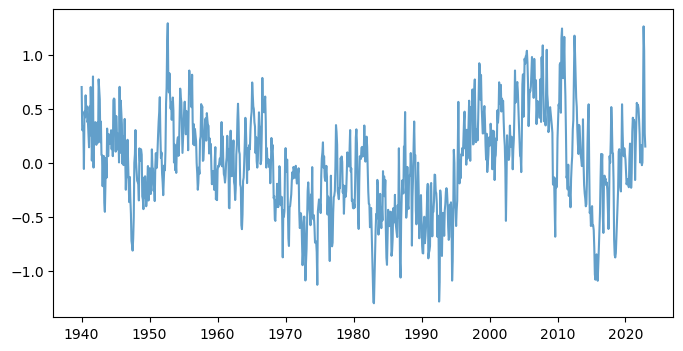

In [11]:
plt.figure(figsize=(8, 4))

plt.plot(AMOC_era5['AMOC_era5'], label='Era5', alpha=.7)

### CLLJ

In [12]:
# units: m/s
CLLJ = to_ts(path + 'CLLJ/cdo-fldmean/CLLJ_u-wind_aggregated.nc', ['lat','lon'], 'u', 'CLLJ', detrend=True)
CLLJ = -CLLJ

### AR precipitation

In [14]:
# ERA5 (m of water equivalent per day)
# tp [mm] = tp [m/day]⋅1000⋅N
ERA5_prec = to_ts(path + 'AR/prec/ERA5_south.nc', ['latitude','longitude'], 'tp', 'SAR_prec', detrend=True)

### mask

In [16]:
# SAR dry season (MJJAS)
pattern = [1,1,1,1,0,0,0,0,0,1,1,1] * 83

## merge + re-index

### ERA5 (1940-2022)

In [20]:
ERA5 = pd.concat([AMOC_era5['AMOC_era5'], CLLJ, ERA5_prec], axis=1)

ERA5 = ERA5.reset_index().rename(columns={'index': 'time'})
ERA5['Southern AR dry season'] = pattern
ERA5

,time,AMOC_era5,CLLJ,SAR_prec,Southern AR dry season
0,1940-01-01,0.700033,-1.014249,-0.000824,1
1,1940-02-01,0.301558,-0.829772,-0.000628,1
2,1940-03-01,0.300496,-0.598130,0.000415,1
3,1940-04-01,0.339456,-0.448275,-0.001216,1
4,1940-05-01,-0.057473,-0.083998,-0.000897,0
...,...,...,...,...,...
991,2022-08-01,0.520212,-0.077329,-0.000274,0
992,2022-09-01,1.261006,-1.009389,-0.001183,0
993,2022-10-01,1.034151,-0.049851,-0.000118,1
994,2022-11-01,0.270090,-0.583495,-0.002414,1


In [21]:
ERA5.to_csv(path + 'ERA5_1940-2022.csv')